# Track 01 Workflow Notebook

This notebook follows the [analysis workflow](../3-workflow.md) step by step. Each numbered section matches a step in that guide, so read them side by side.

The notebook handles the coding. Your team makes the decisions. Cells you need to edit are marked **You decide**. Everything else runs as is.

Run cells from top to bottom with Shift+Enter.

## 0. Setup

Works on your own computer and on Google Colab. On Colab this cell downloads the repository and installs PyDESeq2, which takes about a minute.

In [1]:
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("/content/openbio-datathon-2026").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/Harvard-Undergraduate-OpenBio/openbio-datathon-2026.git", "/content/openbio-datathon-2026"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pydeseq2"], check=True)
    os.chdir("/content/openbio-datathon-2026/track-01/notebooks")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

DATA_DIR = Path("../data")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
print("Setup complete. Data folder:", DATA_DIR.resolve())

Setup complete. Data folder: C:\Users\cngol\OneDrive\Documents\Bioinformatics\OpenBio Datathon\openbio-datathon-2026\track-01\data


## 1. Pick a Question

Choose one from the [starter questions](../starter-questions.md) and write it here. Double-click this cell to edit it.

**You decide:** Our question is: Do early-onset and late-onset preeclampsia tell different biological stories?

## 2. Load and Check the Data

Loads the count table (genes by samples) and the metadata table (one row per sample), then checks that they fit together. If a check prints `False` or a nonzero duplicate count, note it in your analysis plan and tell an organizer. Do not edit the data files.

In [2]:
def load_table(path):
    if not path.exists() or path.stat().st_size == 0:
        print(f"{path.name}: pending release (file is empty for now).")
        return None
    return pd.read_csv(path, index_col=0)

counts = load_table(DATA_DIR / "track01_counts_vt.csv")
metadata = load_table(DATA_DIR / "track01_metadata_vt.csv")

if counts is not None and metadata is not None:
    print(f"Counts: {counts.shape[0]:,} genes x {counts.shape[1]} samples")
    print(f"Metadata: {metadata.shape[0]} samples x {metadata.shape[1]} fields")
    print()
    print("Samples in both tables:      ", len(set(counts.columns) & set(metadata.index)))
    print("Counts are nonnegative:      ", bool((counts.values >= 0).all()))
    print("Counts are whole numbers:    ", bool((counts.values % 1 == 0).all()))
    print("Duplicate genes:             ", int(counts.index.duplicated().sum()))
    print("Duplicate samples:           ", int(counts.columns.duplicated().sum()))
    # Put metadata rows in the same order as the count columns
    metadata = metadata.loc[counts.columns]

Counts: 26,485 genes x 30 samples
Metadata: 30 samples x 20 fields

Samples in both tables:       30
Counts are nonnegative:       True
Counts are whole numbers:     True
Duplicate genes:              0
Duplicate samples:            0


Look at the metadata fields and how many values are missing in each. The [data dictionary](../data/track01_data_dictionary.md) explains every column.

In [3]:
if metadata is not None:
    overview = pd.DataFrame({
        "example_value": metadata.iloc[0],
        "n_missing": metadata.isna().sum(),
        "n_unique": metadata.nunique(),
    })
    display(overview)

,example_value,n_missing,n_unique
geo_accession,GSM6175116,0,30
donor_id,S01,0,30
group,EOPE+FGR,0,5
pe_status,PE,0,2
pe_onset,early_onset,0,2
fgr_status,FGR,0,2
control_type,not_control,0,3
ga_delivery_source,33.4,0,23
ga_delivery_completed_weeks,33,0,10
ga_delivery_extra_days,4,0,8


## 3. Explore the Samples

The PCA plot places samples with similar overall gene activity close together. Change `COLOR_BY` to different metadata columns and rerun the cell to see which fields line up with the main patterns.

Write what you notice in your analysis plan. This guides Step 4.

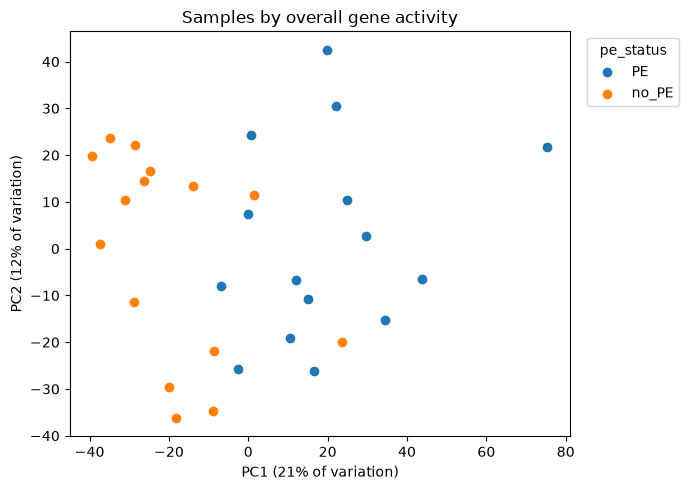

In [41]:
# You decide: a metadata column name to color the points by
COLOR_BY = 'pe_status'

def plot_pca(counts, metadata, color_by=None):
    # Scale each sample to counts per million, then log transform so a few huge genes do not dominate
    log_cpm = np.log2(counts.div(counts.sum(axis=0), axis=1) * 1e6 + 1)
    pca = PCA(n_components=2)
    scores = pca.fit_transform(log_cpm.T)
    fig, ax = plt.subplots(figsize=(7, 5))
    if color_by is None:
        ax.scatter(scores[:, 0], scores[:, 1])
    else:
        values = metadata[color_by]
        if pd.api.types.is_numeric_dtype(values):
            points = ax.scatter(scores[:, 0], scores[:, 1], c=values, cmap="viridis")
            fig.colorbar(points, ax=ax, label=color_by)
        else:
            for level in values.fillna("NA").unique():
                mask = (values.fillna("NA") == level).values
                ax.scatter(scores[mask, 0], scores[mask, 1], label=str(level))
            ax.legend(title=color_by, bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
    ax.set_title("Samples by overall gene activity")
    plt.tight_layout()
    plt.show()

if counts is not None:
    plot_pca(counts, metadata, COLOR_BY)

## 4. Choose a Comparison

Define the two groups you will compare. Use exact column names and values from the metadata table (Section 2 lists them).

- `GROUP_COLUMN`: the column that defines your groups
- `CASE` and `CONTROL`: the two values of that column to compare
- `COVARIATES`: other columns to account for, such as gestational age. Leave as `[]` for none.

Write a short justification for these choices in your analysis plan.

In [5]:
# You decide
GROUP_COLUMN = 'pe_status'   # e.g. "column_name"
CASE = 'PE'           # e.g. "value_for_group_A"
CONTROL = 'no_PE'       # e.g. "value_for_group_B"
COVARIATES = ['ga_delivery_weeks', 'maternal_age_years']       # e.g. ["another_column"]

def build_comparison(counts, metadata):
    if None in (GROUP_COLUMN, CASE, CONTROL):
        print("Fill in GROUP_COLUMN, CASE and CONTROL above, then rerun this cell.")
        return None, None
    used = [GROUP_COLUMN] + list(COVARIATES)
    meta = metadata[metadata[GROUP_COLUMN].isin([CASE, CONTROL])][used].copy()
    n_before = len(meta)
    meta = meta.dropna()
    if len(meta) < n_before:
        print(f"Note: {n_before - len(meta)} sample(s) dropped for missing values in {used}. Report this.")
    meta[GROUP_COLUMN] = meta[GROUP_COLUMN].astype(str)
    print(meta[GROUP_COLUMN].value_counts().to_string())
    return counts[meta.index], meta

comp_counts, comp_meta = (None, None) if counts is None else build_comparison(counts, metadata)

pe_status
PE       15
no_PE    15


## 5. Run the Test

Runs differential expression with PyDESeq2. It adjusts for sequencing depth, then tests every gene for a difference between `CASE` and `CONTROL` that is larger than the natural variation between samples. Expect a few seconds to a few minutes.

In [6]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

results = None
if comp_counts is not None:
    design = "~" + " + ".join(list(COVARIATES) + [GROUP_COLUMN])
    print("Design:", design)
    dds = DeseqDataSet(
        counts=comp_counts.T.astype(int),   # PyDESeq2 wants samples as rows
        metadata=comp_meta,
        design=design,
        quiet=True,
    )
    dds.deseq2()
    stats = DeseqStats(dds, contrast=[GROUP_COLUMN, str(CASE), str(CONTROL)], quiet=True)
    stats.summary()
    results = stats.results_df.sort_values("padj")
    results.to_csv(RESULTS_DIR / "de_results.csv")
    print(f"Tested {len(results):,} genes. Saved to results/de_results.csv")
    display(results.head(10))

Design: ~ga_delivery_weeks + maternal_age_years + pe_status
Tested 26,485 genes. Saved to results/de_results.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
ENG,6068.654828,1.998963,0.208037,9.608711,7.346277e-22,1.223229e-17
SERPINA3,418.561690,6.020915,0.690762,8.716340,2.873394e-18,2.392244e-14
HTRA4,7503.856778,2.685022,0.350746,7.655172,1.930533e-14,1.071510e-10
AMD1,3435.425862,0.812415,0.109865,7.394665,1.417653e-13,5.901337e-10
ABCA7,161.833727,1.359286,0.188962,7.193420,6.318812e-13,2.104291e-09
GPIHBP1,83.041584,1.927809,0.274631,7.019646,2.224304e-12,6.172814e-09
PAM,6397.755114,0.944388,0.139266,6.781180,1.191986e-11,2.478466e-08
ERO1A,1289.963884,1.307423,0.193283,6.764292,1.339631e-11,2.478466e-08
TMEM45A,279.253895,2.059495,0.304030,6.773996,1.252733e-11,2.478466e-08


## 6. Read the Results

- `log2FoldChange`: +1 means twice as high in CASE, −1 means half as high
- `padj`: adjusted p-value, smaller means stronger evidence
- `baseMean`: average count, very low values are unreliable

Set your own cutoffs. Try a few values and note how much the number of passing genes changes.

836 genes pass (512 higher in PE, 324 lower).


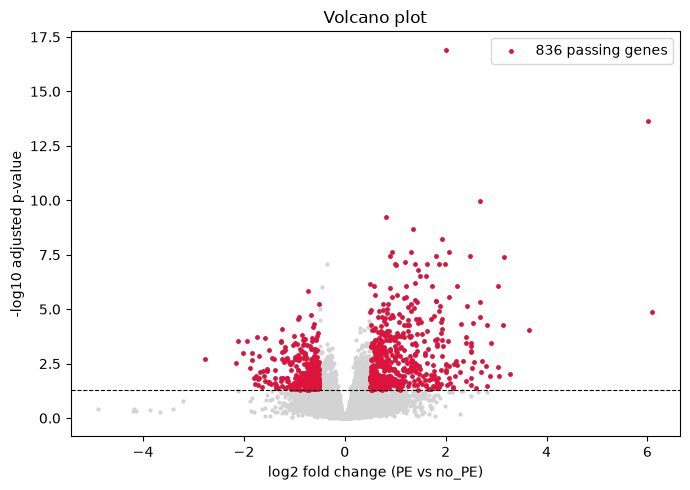

In [37]:
# You decide
PADJ_CUTOFF = 0.05   # e.g. a value between 0 and 1
LFC_CUTOFF = 0.5    # e.g. a minimum absolute log2 fold change, or 0

def passing_genes(results):
    if PADJ_CUTOFF is None or LFC_CUTOFF is None:
        return None
    keep = (results["padj"] < PADJ_CUTOFF) & (results["log2FoldChange"].abs() >= LFC_CUTOFF)
    return results[keep]

def volcano(results, hits, CASE, CONTROL):
    fig, ax = plt.subplots(figsize=(7, 5))
    y = -np.log10(results["padj"].clip(lower=1e-300))
    ax.scatter(results["log2FoldChange"], y, s=4, color="lightgray")
    if hits is not None:
        ax.scatter(hits["log2FoldChange"], -np.log10(hits["padj"].clip(lower=1e-300)), s=6, color="crimson", label=f"{len(hits)} passing genes")
        ax.axhline(-np.log10(PADJ_CUTOFF), ls="--", lw=0.8, color="black")
        ax.legend()
    ax.set_xlabel(f"log2 fold change ({CASE} vs {CONTROL})")
    ax.set_ylabel("-log10 adjusted p-value")
    ax.set_title("Volcano plot")
    plt.tight_layout()
    fig.savefig(RESULTS_DIR / "volcano.png", dpi=300)
    plt.show()

hits = None
if results is not None:
    hits = passing_genes(results)
    if hits is None:
        print("Set PADJ_CUTOFF and LFC_CUTOFF to highlight genes.")
    else:
        print(f"{len(hits)} genes pass ({(hits['log2FoldChange'] > 0).sum()} higher in {CASE}, {(hits['log2FoldChange'] < 0).sum()} lower).")
        hits.to_csv(RESULTS_DIR / "passing_genes_early.csv")
    volcano(results, hits, CASE, CONTROL)

In [12]:
# create a list of both up and down regulated genes for functional analysis by DAVID
infile = open('results/passing_genes.csv', 'r')
outfile_down = open('results/passing_down_genes_DAVID.csv', 'w')
outfile_up = open('results/passing_up_genes_DAVID.csv', 'w')
for line in infile:
    items = line.strip().split(',')
    if items[0] == 'gene':
        continue
    else:
        if float(items[2]) > 0:
            outfile_up.write(items[0] + '\n')
        else:
            outfile_down.write(items[0] + '\n')
infile.close()
outfile_up.close()
outfile_down.close()

## 7. Connect Genes to Cell Types

First, check which passing genes are known markers of broad placental cell types. If many markers of one cell type move in the same direction, a change in cell mix is one possible explanation.

Gene identifiers in the counts table may not be gene symbols. If no genes match, check the data dictionary for how to map them.

In [8]:
markers = pd.read_csv(DATA_DIR / "interpretation" / "track01_marker_matrix.csv")

if hits is not None:
    overlap = markers.merge(hits[["log2FoldChange", "padj"]], left_on="gene_symbol", right_index=True)
    if overlap.empty:
        print("None of your passing genes are in the marker table.")
    else:
        display(overlap.sort_values(["cell_class", "log2FoldChange"]))
else:
    print("Marker table loaded:", markers["cell_class"].nunique(), "cell classes. Set cutoffs in Section 6 to compare.")

,cell_class,compartment,gene_symbol,log2FoldChange,padj
11,decidual_nk_cell,maternal,KLRD1,-0.637364,0.002274
13,decidual_nk_cell,maternal,KIT,1.006797,0.000855
23,endothelial_cell,maternal,CLDN5,0.644322,0.001238
29,perivascular_cell,maternal,PDGFRB,0.574450,0.005670
4,syncytiotrophoblast,fetal,CGA,0.793258,0.040718


Next, look up at least three of your genes in the [Zeisel/Admati gene browser](https://storage.googleapis.com/www_zeisellab/PE_web/pe_web_test_v1.html) (required). Record what you see in the table below; it is saved to `results/browser_lookups.csv` for your submission.

In [ ]:
# You decide: one row per gene you looked up
browser_lookups = pd.DataFrame([
    # {"gene": "GENE_A", "cell_types_expressing": "...", "differs_PE_vs_control": "...", "notes": "..."},
])
if not browser_lookups.empty:
    browser_lookups.to_csv(RESULTS_DIR / "browser_lookups.csv", index=False)
    display(browser_lookups)
else:
    print("Add at least three genes to browser_lookups.")

## 8. Optional: Single-Cell Extension

The pseudobulk files hold counts summed by donor and cell type. To test one cell type, filter both tables to that cell type and rerun Sections 4 to 6 with `counts` and `metadata` replaced by the filtered tables. The data dictionary describes the column layout. Each donor counts once, and the early-onset comparison is exploratory.

In [9]:
pb_counts = load_table(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_counts.csv")
pb_metadata = load_table(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_metadata.csv")
if pb_counts is not None:
    print("Pseudobulk counts:", pb_counts.shape)
    display(pb_metadata.head())

Pseudobulk counts: (33660, 362)


,donor_id,cell_class,compartment,n_cells,total_counts,pe_status,onset_group,clinical_group,early_onset_comparison,fgr_status,...,labor_induction,magnesium_sulfate,anesthesia,ga_delivery_weeks,birthweight_g,birthweight_percentile_dolberg,maternal_age_years,n_libraries,library_ids,qc_flags
pseudobulk_id,,,,,,,,,,,,,,,,,,,,,
PE_early_1__b_cell,PE_early_1,b_cell,immune,19,200845,PE,early,PE_early,exploratory_3_control_vs_10_PE,FGR,...,NaN,yes,spinal,26.400,750,13,32,2,63-1;63-2,fgr_with_birthweight_percentile_ge10
PE_early_10__b_cell,PE_early_10,b_cell,immune,16,168046,PE,early,PE_early,exploratory_3_control_vs_10_PE,no_FGR,...,no,yes,spinal,29.857,1645,73,26,1,119-1,none
PE_early_2__b_cell,PE_early_2,b_cell,immune,16,178170,PE,early,PE_early,exploratory_3_control_vs_10_PE,FGR,...,NaN,yes,general,34.100,1590,7,29,1,86-1,none
PE_early_3__b_cell,PE_early_3,b_cell,immune,11,120252,PE,early,PE_early,exploratory_3_control_vs_10_PE,no_FGR,...,NaN,no,general,35.857,2274,23,35,1,88-1,none
PE_early_4__b_cell,PE_early_4,b_cell,immune,7,76405,PE,early,PE_early,exploratory_3_control_vs_10_PE,no_FGR,...,NaN,yes,spinal,33.143,2845,90,21,1,92-1,none


In [11]:
# pseudobulk data by aggregating scRNA

# load files as dataframes
data_dir = Path("../data/extension/pseudobulk")

counts1 = pd.read_csv(data_dir / "track01_pseudobulk_counts.csv", index_col="gene")
meta1   = pd.read_csv(data_dir / "track01_pseudobulk_donors.csv")

# Donor for each sample = everything before the first "__"
sample_to_donor = counts1.columns.to_series().str.split("__", n=1).str[0]

# Sum all cell types per donor -> one column per donor
donor_counts = counts1.T.groupby(sample_to_donor.values).sum().T

# Align column order to the metadata rows
donor_order = meta1["donor_id"].astype(str).drop_duplicates()
donor_counts = donor_counts[donor_order]        

# Check that donors match between counts and metadata
counts_donors = set(sample_to_donor)
meta_donors   = set(meta1["donor_id"].astype(str))
print("In counts but not metadata:", counts_donors - meta_donors)
print("In metadata but not counts:", meta_donors - counts_donors)
assert counts_donors == meta_donors, "Donor mismatch between counts and metadata"

# checks before file save
print(donor_counts.shape, meta1.shape)
assert donor_counts.columns.is_unique, "Duplicate donor columns"
assert donor_counts.shape[1] == sample_to_donor.nunique(), "Wrong number of donor columns"

# Save (new file; originals are not changed)
donor_counts.to_csv(data_dir / "pseudobulk_counts_by_donor.csv")


# compare new file to original counts
out_path = data_dir / "pseudobulk_counts_by_donor.csv"
donor_counts.to_csv(out_path)
saved = pd.read_csv(out_path, index_col="gene")
# check for same genes (same number, same names, same order)
assert saved.shape[0] == counts1.shape[0], f"Gene count differs: {saved.shape[0]} vs {counts1.shape[0]}"
assert (saved.index == counts1.index).all(), "Gene names or order differ"
#check for row sums (total counts per gene across all samples/donors) are equal
orig_row_sums  = counts1.sum(axis=1)
saved_row_sums = saved.sum(axis=1)
assert np.allclose(orig_row_sums, saved_row_sums), "Per-gene sums differ"

#print results
print("Genes:", counts1.shape[0], "->", saved.shape[0])
print("Per-gene sums match:", np.allclose(orig_row_sums, saved_row_sums))
print("Total counts match:", np.isclose(orig_row_sums.sum(), saved_row_sums.sum()))
print("Columns:", counts1.shape[1], "->", saved.shape[1])


In counts but not metadata: set()
In metadata but not counts: set()
(33660, 26) (26, 19)
Genes: 33660 -> 33660
Per-gene sums match: True
Total counts match: True
Columns: 362 -> 26


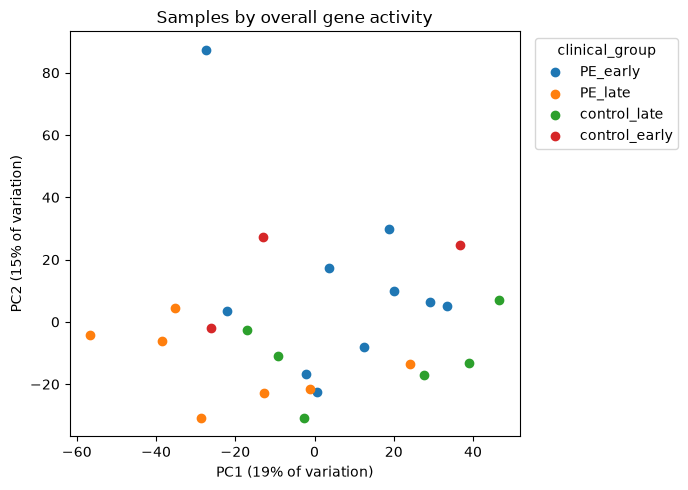

33660 -> 20578 genes
group_pooled
PE_early    10
control      9
PE_late      7
Name: count, dtype: int64


In [56]:
counts2 = pd.read_csv(data_dir / "pseudobulk_counts_by_donor.csv", index_col="gene")
metadata2 = pd.read_csv(data_dir / "track01_pseudobulk_donors.csv")

# PCA
COLOR_BY2 = 'clinical_group'
plot_pca(counts2, metadata2, COLOR_BY2)
# filter genes by at least 10 reads in at least 3 samples
keep = (counts2 >= 10).sum(axis=1) >= 3
counts2_filt = counts2.loc[keep]
print(counts2.shape[0], "->", counts2_filt.shape[0], "genes")
metadata2 = metadata2.set_index("donor_id").loc[counts2.columns]
metadata2["group_pooled"] = metadata2["clinical_group"].replace({
    "control_early": "control",
    "control_late":  "control",
})

In [57]:
# Differential gene analysis for early vs late onset
GROUP_COLUMN2 = 'group_pooled'
CASE2 = 'PE_early'
CONTROL2 = 'PE_late'
COVARIATES2 = ['maternal_age_years']

def build_comparison2(counts2, metadata2, GROUP_COLUMN2, CASE2, CONTROL2, COVARIATES2):
    used = [GROUP_COLUMN2] + list(COVARIATES2)
    meta = metadata2[metadata2[GROUP_COLUMN2].isin([CASE2, CONTROL2])][used].copy()
    n_before = len(meta)
    meta = meta.dropna()
    if len(meta) < n_before:
        print(f"Note: {n_before - len(meta)} sample(s) dropped for missing values in {used}. Report this.")
    meta[GROUP_COLUMN2] = meta[GROUP_COLUMN2].astype(str)
    print(meta[GROUP_COLUMN2].value_counts().to_string())
    return counts2[meta.index], meta

comp_counts2, comp_meta2 = build_comparison2(counts2_filt, metadata2, GROUP_COLUMN2, CASE2, CONTROL2, COVARIATES2)

group_pooled
PE_early    10
PE_late      7


In [58]:
# early vs late
results2 = None
design2 = "~" + " + ".join(list(COVARIATES2) + [GROUP_COLUMN2])
print("Design:", design2)
dds2 = DeseqDataSet(
        counts=comp_counts2.T.astype(int),
        metadata=comp_meta2,
        design=design2,
        quiet=True,
    )
dds2.deseq2()
stats = DeseqStats(dds2, contrast=[GROUP_COLUMN2, str(CASE2), str(CONTROL2)], quiet=True)
stats.summary()
results2 = stats.results_df.sort_values("padj")
results2.to_csv(RESULTS_DIR / "de_early_late_results.csv")
print(f"Tested {len(results2):,} genes. Saved to results/de_early_late_results.csv")
display(results2.head(10))

Design: ~maternal_age_years + group_pooled
Tested 20,578 genes. Saved to results/de_early_late_results.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
CTD-2017F17.2,173.219759,0.827830,0.129882,6.373686,1.845379e-10,0.000003
CTD-2311M21.3,60.173881,1.295019,0.234703,5.517700,3.434653e-08,0.000312
MTMR7,22.135332,1.889043,0.353576,5.342683,9.158061e-08,0.000555
SGOL2,359.509135,0.777304,0.147222,5.279818,1.293125e-07,0.000588
DND1,40.943407,-2.377508,0.455336,-5.221435,1.775422e-07,0.000646
KLF3,3811.162151,-0.411435,0.079776,-5.157399,2.504041e-07,0.000759
UHRF1,111.583821,0.947897,0.189257,5.008513,5.485216e-07,0.001425
MME,2422.304100,1.082446,0.223288,4.847762,1.248621e-06,0.002838
ST8SIA1,73.372742,2.433378,0.512102,4.751743,2.016707e-06,0.003053


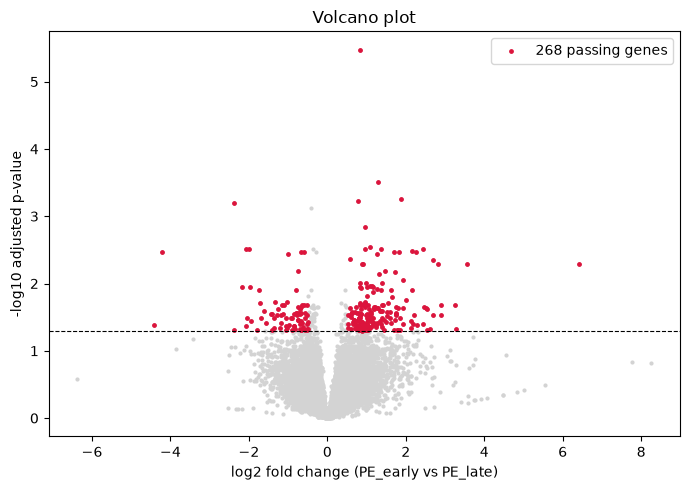

In [59]:
# early vs late volcano plot
hits2 = passing_genes(results2)
hits2.to_csv(RESULTS_DIR / "passing_genes_early_late.csv")
volcano(results2, hits2, CASE2, CONTROL2)

In [36]:
# create a list of both up and down regulated genes for functional analysis by DAVID - early/late
infile = open('results/passing_genes_early_late.csv', 'r')
outfile_down = open('results/passing_down_genes_early_late_DAVID.csv', 'w')
outfile_up = open('results/passing_up_genes_early_late_DAVID.csv', 'w')
for line in infile:
    items = line.strip().split(',')
    if items[0] == 'gene':
        continue
    else:
        if float(items[2]) > 0:
            outfile_up.write(items[0] + '\n')
        else:
            outfile_down.write(items[0] + '\n')
infile.close()
outfile_up.close()
outfile_down.close()

group_pooled
control    9
PE_late    7
Design: ~maternal_age_years + group_pooled
Tested 20,578 genes. Saved to results/de_late_results.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
IQGAP2,5751.151404,-0.766806,0.127773,-6.001314,1.957268e-09,0.000034
IFI44L,1573.560480,1.245034,0.210789,5.906533,3.493833e-09,0.000034
CAPS,1548.489996,-1.114265,0.192337,-5.793307,6.901384e-09,0.000045
RP11-390D11.1,16.947596,-2.712612,0.491111,-5.523416,3.324719e-08,0.000129
LRRC7,60.507065,-2.328802,0.421433,-5.525908,3.277856e-08,0.000129
PCOLCE2,5269.656373,-1.095793,0.207304,-5.285920,1.250745e-07,0.000404
ST7,631.436324,-0.558877,0.106643,-5.240618,1.600400e-07,0.000443
HERC6,363.752880,0.696313,0.136706,5.093504,3.515065e-07,0.000852
MCOLN3,472.864793,-1.490246,0.307229,-4.850598,1.230899e-06,0.002651


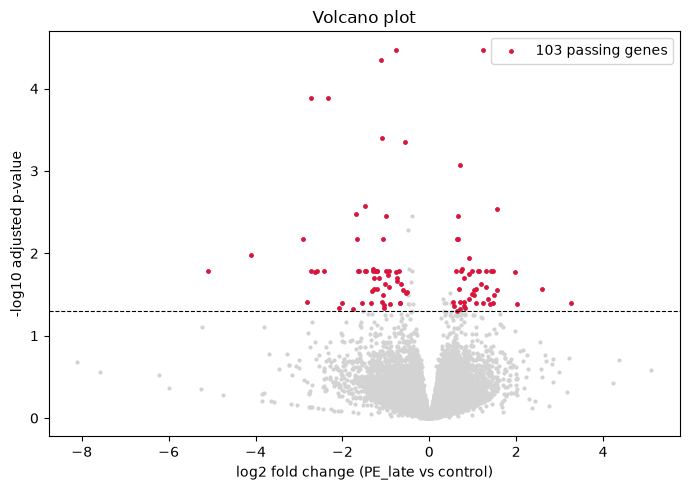

In [60]:
# late vs control (late)
CASE3 = 'PE_late'
CONTROL3 = 'control'
comp_counts3, comp_meta3 = build_comparison2(counts2_filt, metadata2, GROUP_COLUMN2, CASE3, CONTROL3, COVARIATES2)

results3 = None
design3 = "~" + " + ".join(list(COVARIATES2) + [GROUP_COLUMN2])
print("Design:", design3)
dds3 = DeseqDataSet(
        counts=comp_counts3.T.astype(int),
        metadata=comp_meta3,
        design=design3,
        quiet=True,
    )
dds3.deseq2()
stats = DeseqStats(dds3, contrast=[GROUP_COLUMN2, str(CASE3), str(CONTROL3)], quiet=True)
stats.summary()
results3 = stats.results_df.sort_values("padj")
results3.to_csv(RESULTS_DIR / "de_late_results.csv")
print(f"Tested {len(results2):,} genes. Saved to results/de_late_results.csv")
display(results3.head(10))

hits3 = passing_genes(results3)
hits3.to_csv(RESULTS_DIR / "passing_genes_late.csv")
volcano(results3, hits3, CASE3, CONTROL3)

group_pooled
PE_early    10
control      9
Design: ~maternal_age_years + group_pooled
Tested 20,578 genes. Saved to results/de_early_late_results.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
PSG3,526.482117,3.042371,0.469807,6.475783,9.432181e-11,0.000002
PI16,154.060319,2.190686,0.352770,6.209949,5.300193e-10,0.000005
PSG6,133.832081,1.987740,0.329885,6.025548,1.685373e-09,0.000012
LEP,163.419860,3.298593,0.576464,5.722112,1.052078e-08,0.000054
TMEM176B,5855.425559,-1.040995,0.188329,-5.527542,3.247487e-08,0.000134
PSG2,748.071011,2.504940,0.469192,5.338840,9.354331e-08,0.000321
PSG5,578.100163,2.195175,0.414618,5.294453,1.193731e-07,0.000351
C5orf46,16.427167,4.028034,0.768681,5.240190,1.604117e-07,0.000413
LAMA3,277.102715,2.442083,0.473878,5.153401,2.558045e-07,0.000585


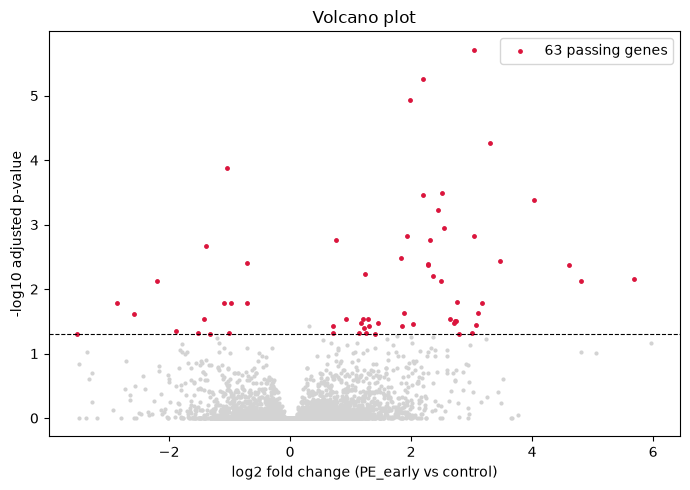

In [61]:
# early vs control (early) from single cell
CASE4 = 'PE_early'
CONTROL4 = 'control'
comp_counts4, comp_meta4 = build_comparison2(counts2_filt, metadata2, GROUP_COLUMN2, CASE4, CONTROL4, COVARIATES2)

results4 = None
design4 = "~" + " + ".join(list(COVARIATES2) + [GROUP_COLUMN2])
print("Design:", design4)
dds4 = DeseqDataSet(
        counts=comp_counts4.T.astype(int),
        metadata=comp_meta4,
        design=design4,
        quiet=True,
    )
dds4.deseq2()
stats = DeseqStats(dds4, contrast=[GROUP_COLUMN2, str(CASE4), str(CONTROL4)], quiet=True)
stats.summary()
results4 = stats.results_df.sort_values("padj")
results4.to_csv(RESULTS_DIR / "de_earlysc_results.csv")
print(f"Tested {len(results4):,} genes. Saved to results/de_early_late_results.csv")
display(results4.head(10))

hits4 = passing_genes(results4)
hits4.to_csv(RESULTS_DIR / "passing_genes_earlysc.csv")
volcano(results4, hits4, CASE4, CONTROL4)

In [44]:
%pip install matplotlib-venn

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for matplotlib-venn: filename=matplotlib_venn-1.1.2-py3-none-any.whl size=45439 sha256=6fd8882e64d5d4d5f598a32dc2ee45f454b276f16c5a135a087255868df4b562
  Stored in directory: c:\users\cngol\appdata\local\pip\cache\wheels\c4\16\4a\93374cd955bbe0553a8ce74db7f0fbd5fcc876e19fb78bd601
Successfully built matplotlib-venn
Note: you may need to restart the kernel to use updated packages.


Early vs control: 48 up, 15 down
Late PE vs control: 45 up, 58 down
Early vs late PE: 189 up, 79 down


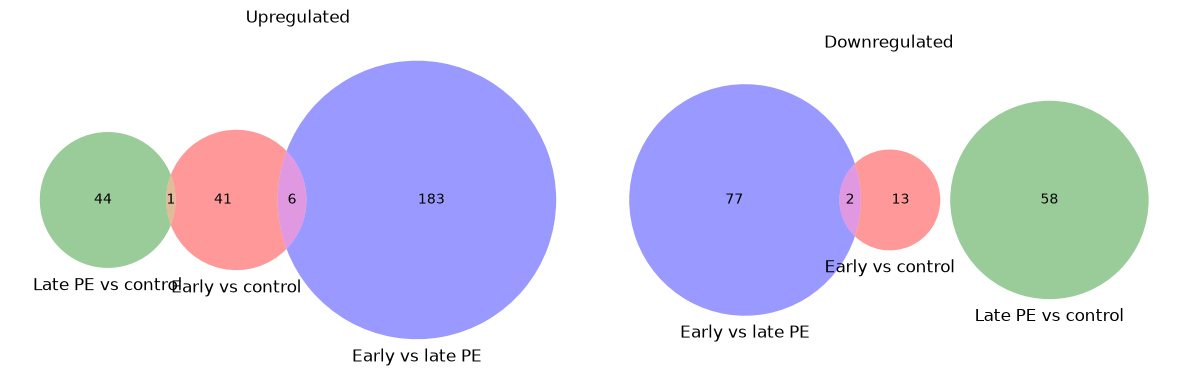

In [66]:
from matplotlib_venn import venn3     # %pip install matplotlib-venn if needed

# Edit these file names to match your saved significant-gene files
files = {
    "Early vs control": RESULTS_DIR / "passing_genes_earlysc.csv",
    "Late PE vs control":  RESULTS_DIR / "passing_genes_late.csv",
    "Early vs late PE":    RESULTS_DIR / "passing_genes_early_late.csv",
}

up, down = {}, {}
for name, path in files.items():
    df = pd.read_csv(path, index_col=0)          # assumes gene names are the first column
    up[name]   = set(df.index[df["log2FoldChange"] > 0])
    down[name] = set(df.index[df["log2FoldChange"] < 0])
    print(f"{name}: {len(up[name])} up, {len(down[name])} down")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, sets, title in [(axes[0], up, "Upregulated"), (axes[1], down, "Downregulated")]:
    venn3(list(sets.values()), set_labels=list(sets.keys()), ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

## Next

Go to [Step 4: Submit](../4-submit.md). Save the figures you want to use, and fill in the hypothesis card.